# Où envoyer l'aide en premier ?

Une ONG vient de réunir 10 millions de dollars. Elle ne peut pas aider 167 pays à la fois, et personne ne lui a remis la liste des plus urgents. Elle a seulement quelques chiffres sur chacun d'eux.

Nous allons laisser K-Means rapprocher les pays qui se ressemblent, puis nous servir des groupes obtenus pour décider.

In [21]:
import matplotlib.pyplot as plt # feuille de dessin
import numpy as np # bibliothèque de calcul scientifique
import pandas as pd
import plotly.express as px # bibliothèque de visualisation interactive (cartes du mondes interactive)
import seaborn as sns # bibliothèque de visualisation statistique

from sklearn.cluster import KMeans
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme() # style de visualisation par défaut

## Les données

Le fichier vient de Kaggle : [Unsupervised Learning on Country Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data).

In [22]:
pays = pd.read_csv("Country-data.csv")

pays.columns = [
    "Pays",
    "Mortalité infantile",
    "Exportations",
    "Santé",
    "Importations",
    "Revenu",
    "Inflation",
    "Espérance de vie",
    "Fécondité",
    "PIB par habitant",
]

pays["Pays"] = pays["Pays"].replace({
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Congo, Rep.": "Republic of the Congo",
})

pays.head()

,Pays,Mortalité infantile,Exportations,Santé,Importations,Revenu,Inflation,Espérance de vie,Fécondité,PIB par habitant
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [23]:
pays.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Pays                 167 non-null    str    
 1   Mortalité infantile  167 non-null    float64
 2   Exportations         167 non-null    float64
 3   Santé                167 non-null    float64
 4   Importations         167 non-null    float64
 5   Revenu               167 non-null    int64  
 6   Inflation            167 non-null    float64
 7   Espérance de vie     167 non-null    float64
 8   Fécondité            167 non-null    float64
 9   PIB par habitant     167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


In [24]:
indicateurs = pays.drop(columns="Pays").astype(float)
indicateurs.describe()

,Mortalité infantile,Exportations,Santé,Importations,Revenu,Inflation,Espérance de vie,Fécondité,PIB par habitant
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


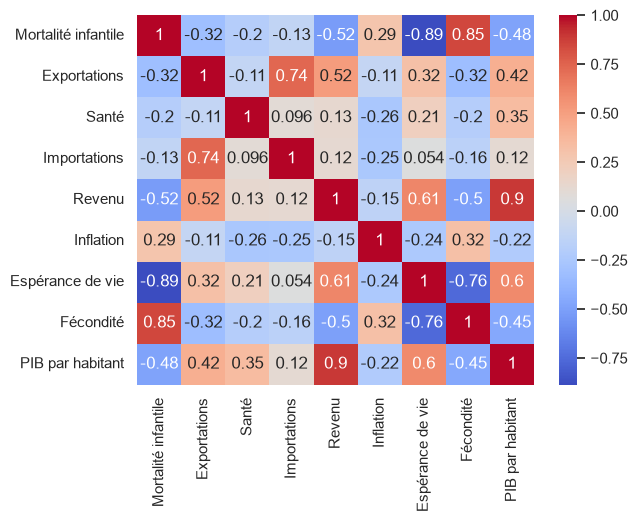

In [25]:
sns.heatmap(indicateurs.corr(), annot=True, cmap="coolwarm")
plt.show()

La mortalité infantile, l'espérance de vie, la fécondité, le revenu et le PIB évoluent ensemble. Les exportations, les importations et l'inflation suivent leur propre chemin.

## Des échelles trop différentes

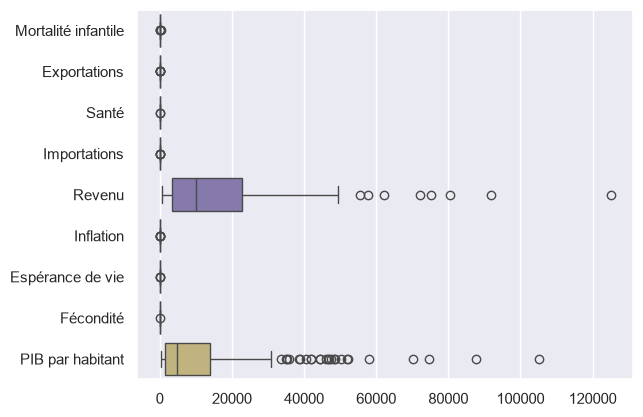

In [26]:
sns.boxplot(data=indicateurs, orient="h")
plt.show()

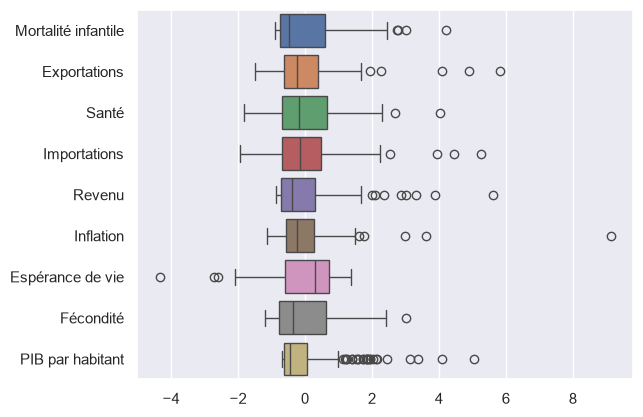

In [27]:
normaliseur = StandardScaler().set_output(transform="pandas")
normalises = normaliseur.fit_transform(indicateurs)

sns.boxplot(data=normalises, orient="h")
plt.show()

Le revenu se compte en milliers, la fécondité en unités. K-Means mesure des distances : sans mise à l'échelle, il ne verrait que le revenu et le PIB.

Pour le vérifier, plaçons les pays sur un repère avec deux indicateurs.

In [28]:
def dessiner(modele, donnees, repere, titre):
    axe_x, axe_y = donnees.columns
    groupes = modele.fit_predict(donnees)
    centres = donnees.groupby(groupes).mean()

    DecisionBoundaryDisplay.from_estimator(modele, donnees, ax=repere, plot_method="contour")
    sns.scatterplot(data=donnees, x=axe_x, y=axe_y, hue=groupes, palette="colorblind", clip_on=False, legend=False, ax=repere)
    sns.scatterplot(data=centres, x=axe_x, y=axe_y, color="black", marker="X", s=200, ax=repere)
    repere.set_title(titre)

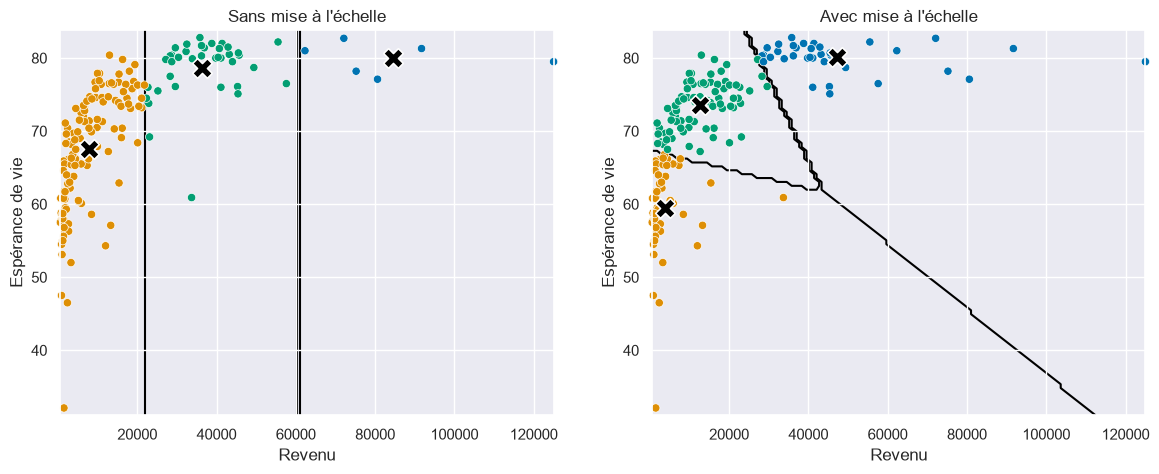

In [29]:
deux_indicateurs = indicateurs[["Revenu", "Espérance de vie"]]

sans_echelle = KMeans(n_clusters=3, n_init=10, random_state=0)
avec_echelle = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=0))

figure, reperes = plt.subplots(1, 2, figsize=(14, 5))
dessiner(sans_echelle, deux_indicateurs, reperes[0], "Sans mise à l'échelle")
dessiner(avec_echelle, deux_indicateurs, reperes[1], "Avec mise à l'échelle")
plt.show()

À gauche, seul le revenu sépare les pays. À droite, l'espérance de vie compte aussi.

## K-Means pas à pas

Trois centres sont posés au hasard. Chaque pays rejoint le plus proche, les centres se replacent au milieu de leur groupe, et on recommence jusqu'à ce que plus rien ne bouge.

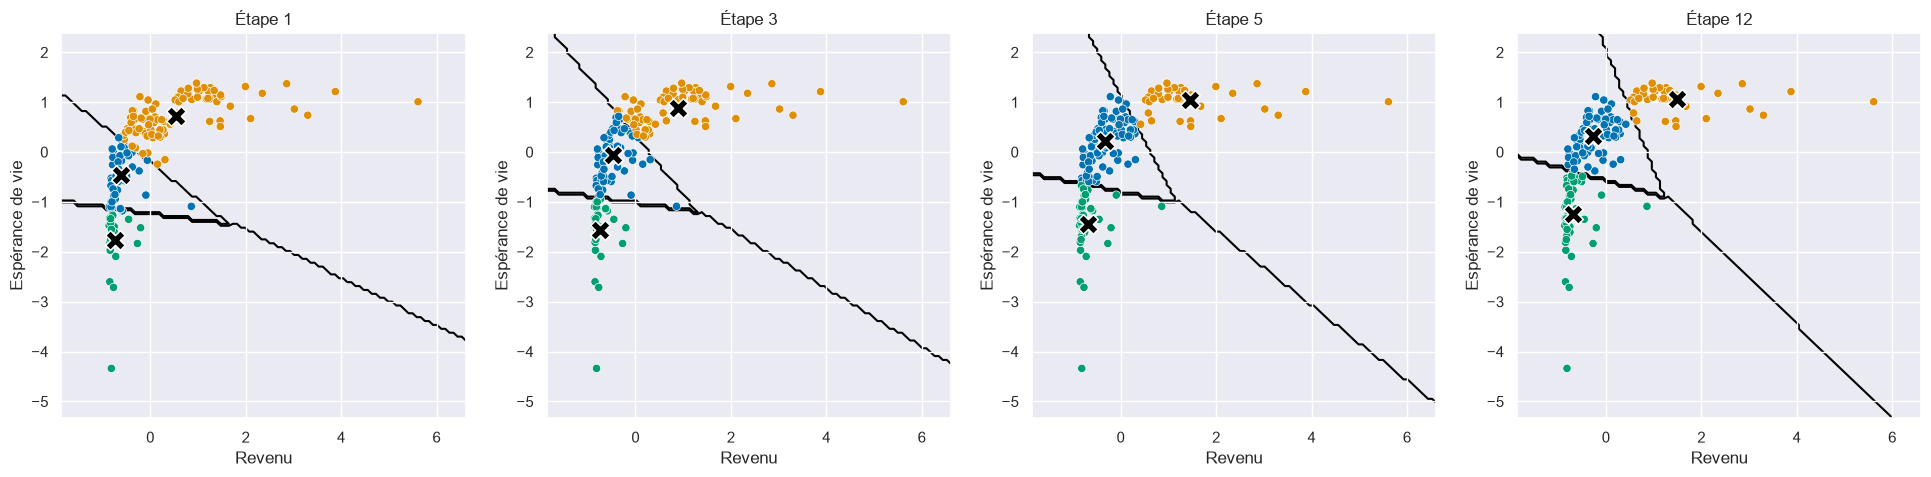

In [30]:
deux_normalises = normalises[["Revenu", "Espérance de vie"]]

figure, reperes = plt.subplots(1, 4, figsize=(24, 5))

for etapes, repere in zip([1, 3, 5, 12], reperes):
    modele = KMeans(n_clusters=3, init="random", n_init=1, max_iter=etapes, random_state=1)
    dessiner(modele, deux_normalises, repere, f"Étape {etapes}")

plt.show()

Le résultat dépend du point de départ. Comparons 30 départs au hasard et 30 départs avec `k-means++`.

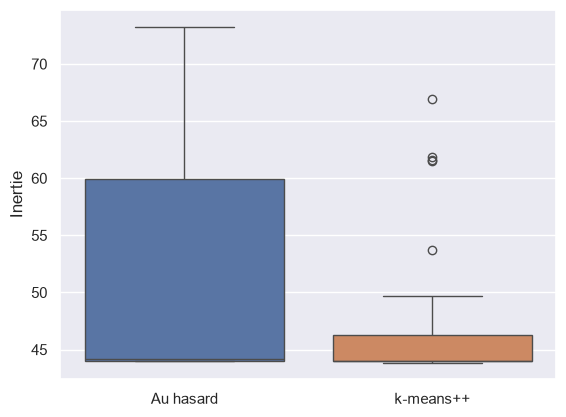

In [31]:
def inertie(depart, tirage):
    modele = KMeans(n_clusters=5, init=depart, n_init=1, random_state=tirage)
    return modele.fit(deux_normalises).inertia_


tirages = range(30)

departs = pd.DataFrame({
    "Au hasard": [inertie("random", tirage) for tirage in tirages],
    "k-means++": [inertie("k-means++", tirage) for tirage in tirages],
})

sns.boxplot(data=departs)
plt.ylabel("Inertie")
plt.show()

## Combien de groupes ?

In [32]:
def comparer_k(donnees):
    valeurs_de_k = range(2, 11)
    modeles = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(donnees) for k in valeurs_de_k]

    inerties = [modele.inertia_ for modele in modeles]
    silhouettes = [silhouette_score(donnees, modele.labels_) for modele in modeles]

    figure, reperes = plt.subplots(1, 2, figsize=(14, 4))
    sns.lineplot(x=valeurs_de_k, y=inerties, marker="o", ax=reperes[0]).set_title("Méthode du coude")
    sns.lineplot(x=valeurs_de_k, y=silhouettes, marker="o", ax=reperes[1]).set_title("Silhouette")
    plt.show()

    print("Meilleure silhouette :", round(max(silhouettes), 2), "avec", valeurs_de_k[np.argmax(silhouettes)], "groupes")

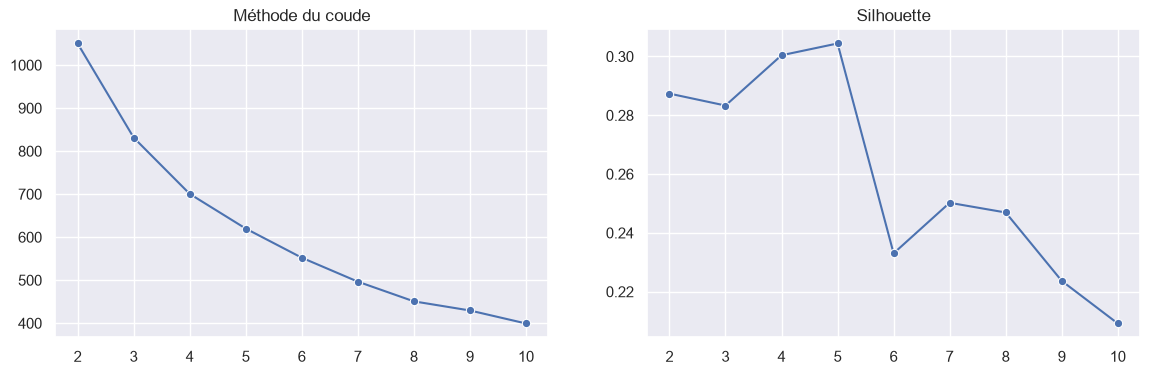

Meilleure silhouette : 0.3 avec 5 groupes


In [33]:
comparer_k(normalises)

Avec les neuf indicateurs, le coude est peu visible et la silhouette reste basse. Regardons de quoi sont faits les cinq groupes proposés.

In [34]:
cinq_groupes = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(normalises)

pays.groupby(cinq_groupes)["Pays"].agg(["count", "first", "last"])

,count,first,last
0,1,Nigeria,Nigeria
1,3,Luxembourg,Singapore
2,30,Australia,United States
3,47,Afghanistan,Zambia
4,86,Albania,Vietnam


Deux groupes sont minuscules. Cherchons quels indicateurs les isolent : 0 correspond à la moyenne des pays, et plus une valeur s'en éloigne, plus elle est extrême.

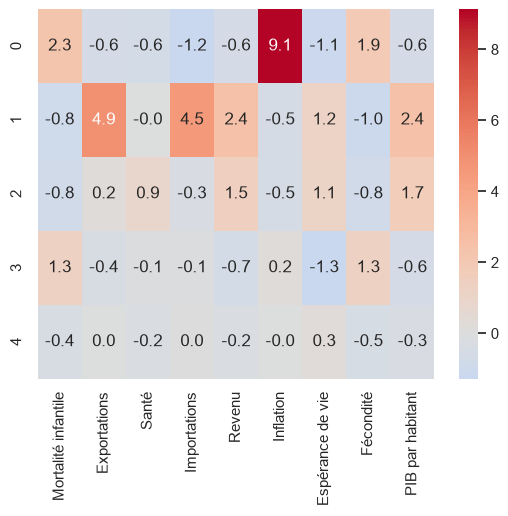

In [35]:
profils = normalises.groupby(cinq_groupes).mean()

sns.heatmap(profils, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.show()

Le groupe 1 isole due a son inflation.
Le groupe 2 est isole due aux exportations et importations de ses pays.

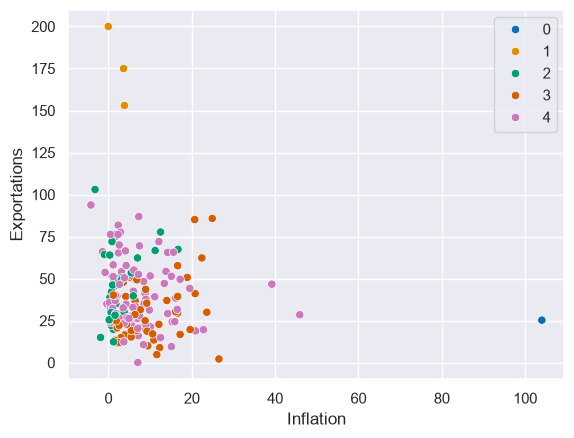

In [36]:
sns.scatterplot(data=indicateurs, x="Inflation", y="Exportations", hue=cinq_groupes, palette="colorblind")
plt.show()

Le Nigeria forme un groupe à lui seul à cause de son inflation. Le Luxembourg, Malte et Singapour en forment un autre à cause de leur commerce. Ces valeurs extrêmes occupent deux groupes sur cinq et ne disent rien de l'urgence.

## Choisir les bons indicateurs

Gardons les cinq indicateurs qui évoluent ensemble.

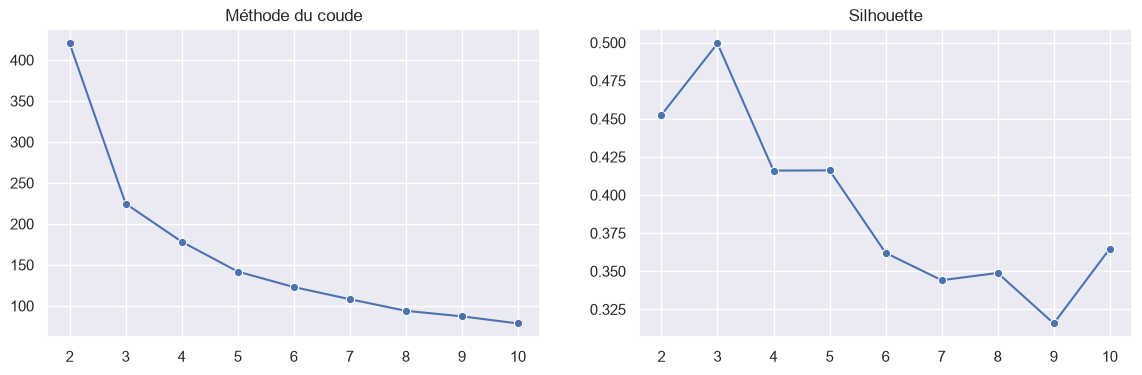

Meilleure silhouette : 0.5 avec 3 groupes


In [37]:
retenus = ["Mortalité infantile", "Espérance de vie", "Fécondité", "Revenu", "PIB par habitant"]

comparer_k(normalises[retenus])

Le coude et la silhouette désignent maintenant le même nombre : trois.

## Les trois groupes

In [38]:
modele = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=0))
groupes = modele.fit_predict(indicateurs[retenus])


def ordonner(groupes):
    mortalite = pays["Mortalité infantile"].groupby(groupes).mean()
    return mortalite.rank(ascending=False).astype(int).astype(str)


ordre = ordonner(groupes)
pays["Priorité"] = ordre[groupes].values

pays.groupby("Priorité")[retenus].mean().round(1)

,Mortalité infantile,Espérance de vie,Fécondité,Revenu,PIB par habitant
Priorité,,,,,
1,92.8,59.1,5.0,3710.1,1854.1
2,21.4,73.1,2.3,12359.2,6854.3
3,5.5,80.1,1.9,47820.6,43776.5


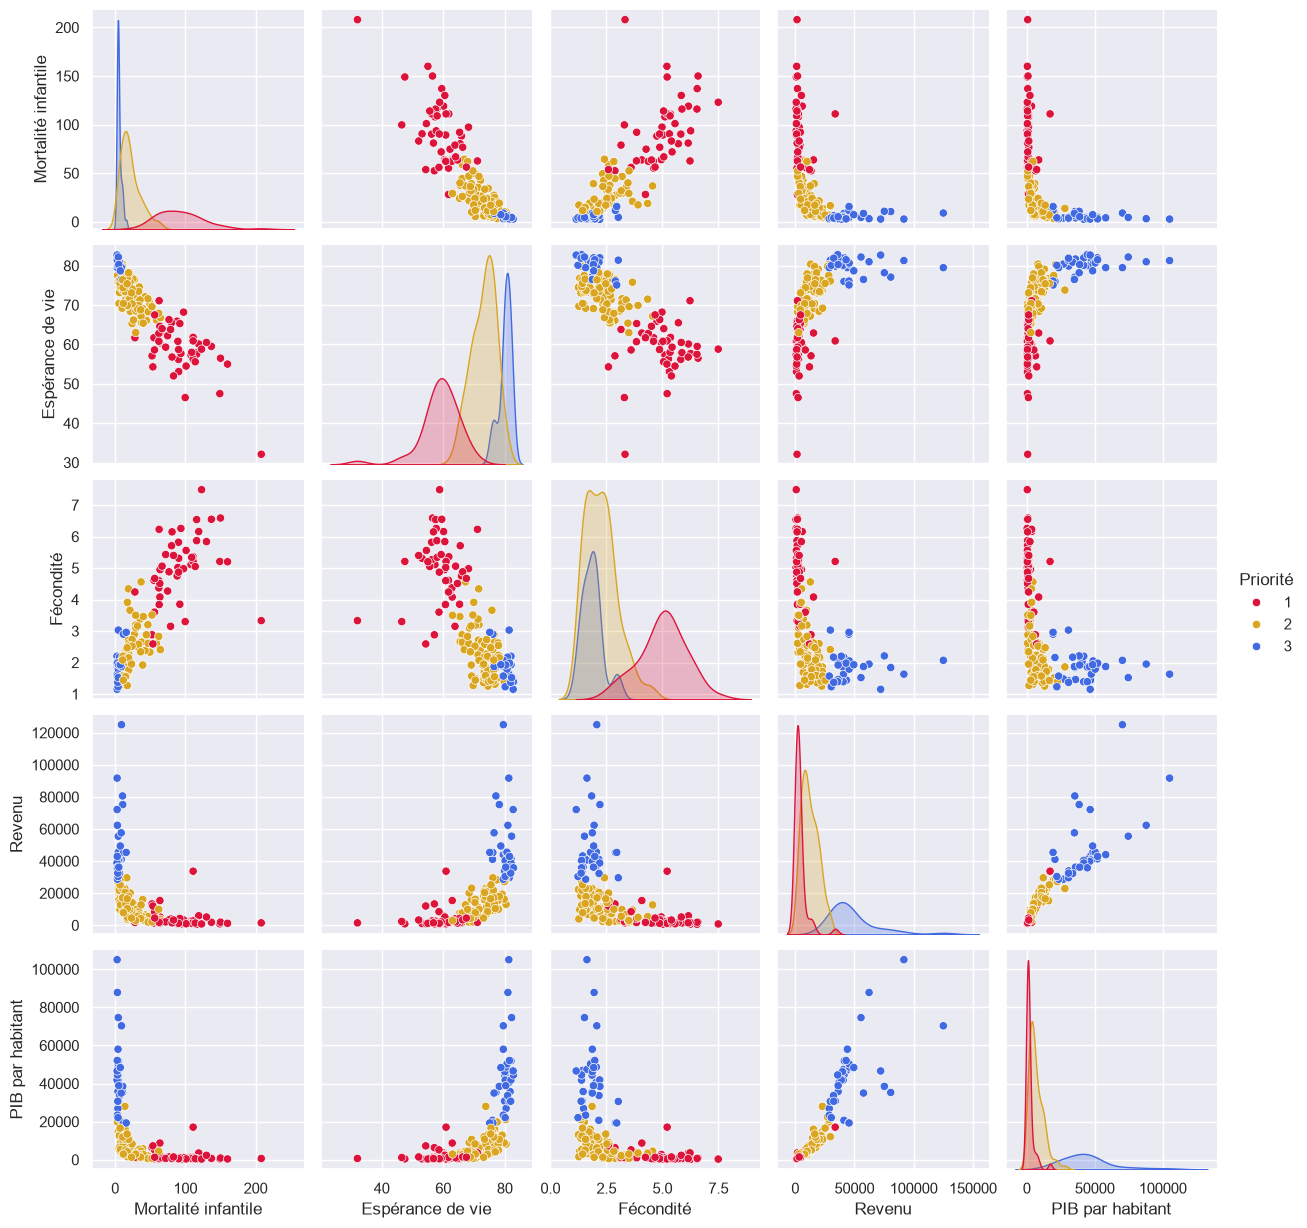

In [39]:
couleurs = {
    "1": "crimson",
    "2": "goldenrod",
    "3": "royalblue",
}

sns.pairplot(pays, vars=retenus, hue="Priorité", palette=couleurs)
plt.show()

In [40]:
px.choropleth(
    pays,
    locations="Pays",
    locationmode="country names",
    color="Priorité",
    color_discrete_map=couleurs,
    category_orders={"Priorité": list(couleurs)},
    hover_name="Pays",
    hover_data=retenus,
    projection="natural earth",
    center={"lat": 0, "lon": 0},
)

In [41]:
urgents = pays[pays["Priorité"] == "1"].sort_values("Mortalité infantile", ascending=False)

print(len(urgents), "pays en priorité 1")
urgents[["Pays"] + retenus].head(10)

47 pays en priorité 1


,Pays,Mortalité infantile,Espérance de vie,Fécondité,Revenu,PIB par habitant
66,Haiti,208.0,32.1,3.33,1500,662
132,Sierra Leone,160.0,55.0,5.20,1220,399
32,Chad,150.0,56.5,6.59,1930,897
31,Central African Republic,149.0,47.5,5.21,888,446
97,Mali,137.0,59.5,6.55,1870,708
113,Nigeria,130.0,60.5,5.84,5150,2330
112,Niger,123.0,58.8,7.49,814,348
3,Angola,119.0,60.1,6.16,5900,3530
25,Burkina Faso,116.0,57.9,5.87,1430,575
37,Democratic Republic of the Congo,116.0,57.5,6.54,609,334
